In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings

In [3]:
df = pd.read_csv('loan_data_set.csv')
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [4]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
df.shape

(614, 13)

In [6]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [7]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [9]:
df.size

7982

In [10]:
df.isnull().sum()            #data cleaning

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [11]:
df.duplicated().sum()        #checking for duplicates

np.int64(0)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])  #filling missing values with mode - mode imputation

In [14]:
df['Married'].mode()

0    Yes
Name: Married, dtype: str

In [15]:
df['Married'] = df['Married'].fillna(df['Married'].mode()[0])  #filling missing values with mode - mode imputation

In [16]:
df['Married'].isnull().sum()

np.int64(0)

In [17]:
df['Dependents'].mode()

0    0
Name: Dependents, dtype: str

In [18]:
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])  #filling missing values with mode - mode imputation

In [19]:
df['Dependents'].isnull().sum()

np.int64(0)

In [20]:
df['Self_Employed'].mode()
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])  #filling missing values with mode - mode imputation
df['Self_Employed'].isnull().sum()

np.int64(0)

In [21]:
df['LoanAmount'].median()
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())  #filling missing values with median - median imputation
df['LoanAmount'].isnull().sum()

np.int64(0)

In [22]:
df['Loan_Amount_Term'].mode()
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])  #filling missing values with mode - mode imputation
df['Loan_Amount_Term'].isnull().sum()

np.int64(0)

In [23]:
df['Credit_History'].mode()
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])  #filling missing values with mode - mode imputation
df['Credit_History'].isnull().sum()

np.int64(0)

In [24]:
df.isnull().sum().sum()

np.int64(0)

In [25]:
df.shape

(614, 13)

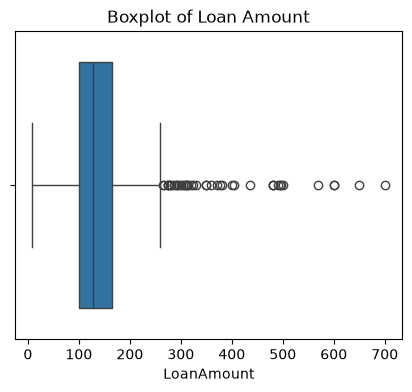

<Figure size 640x480 with 0 Axes>

In [26]:
#outlier detection - interquartile range method and boxplot visualization
#boxplot visualization

plt.figure(figsize=(5,4))
sns.boxplot(x='LoanAmount', data=df) 
plt.title('Boxplot of Loan Amount')
plt.show()
plt.savefig('boxplot_loan_amount.png')  #save the boxplot as an image file

In [27]:
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)

Q1: 100.25
Q3: 164.75
IQR: 64.5
Lower bound: 3.5
Upper bound: 261.5


In [28]:
outliers = df[
    (df['LoanAmount'] < lower) | (df['LoanAmount'] > upper)
]
print("Number of potential outliers in LoanAmount:", outliers.shape[0])

Number of potential outliers in LoanAmount: 41


In [29]:
#checking other columns for outliers

columns = ['ApplicantIncome', 'CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    print(f"Number of potential outliers in {col}: {outliers.shape[0]}")

Number of potential outliers in ApplicantIncome: 50
Number of potential outliers in CoapplicantIncome: 18
Number of potential outliers in Loan_Amount_Term: 88
Number of potential outliers in Credit_History: 89


EXPLORATORY DATA ANALYSIS


In [30]:
df['Loan_Status'].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

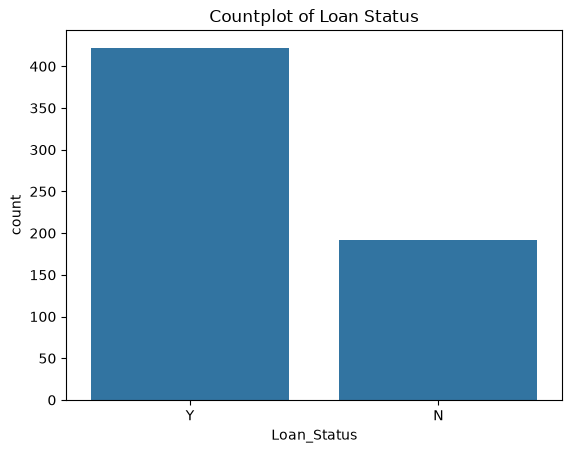

<Figure size 640x480 with 0 Axes>

In [31]:
sns.countplot(x='Loan_Status', data=df)
plt.title('Countplot of Loan Status')
plt.show()
plt.savefig('countplot_loan_status.png')  #save the countplot as an image file

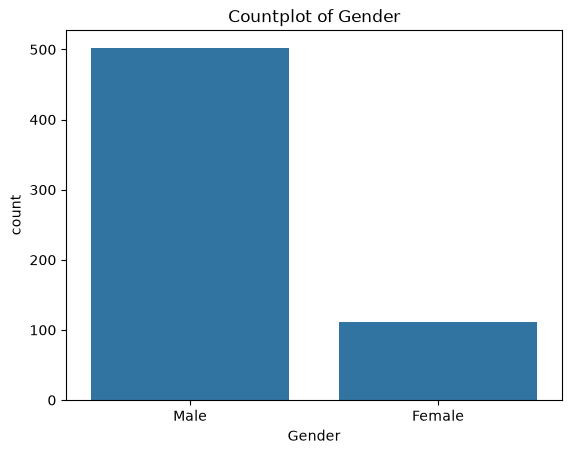

<Figure size 640x480 with 0 Axes>

In [32]:
sns.countplot(x='Gender', data=df)
plt.title('Countplot of Gender')
plt.show()
plt.savefig('countplot_gender.png')  #save the countplot as an image file

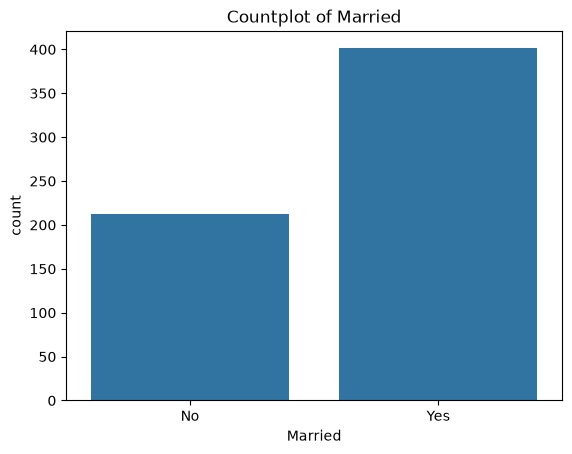

<Figure size 640x480 with 0 Axes>

In [33]:
sns.countplot(x='Married', data=df)
plt.title('Countplot of Married')
plt.show()
plt.savefig('countplot_married.png')  #save the countplot as an image file

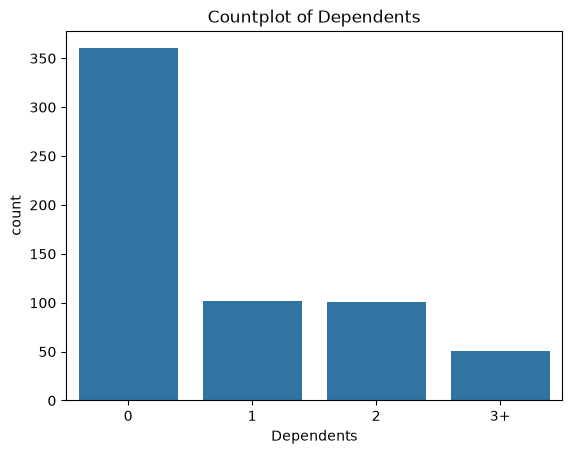

<Figure size 640x480 with 0 Axes>

In [34]:
sns.countplot(x='Dependents', data=df)
plt.title('Countplot of Dependents')
plt.show()
plt.savefig('countplot_dependents.png')  #save the countplot as an image file

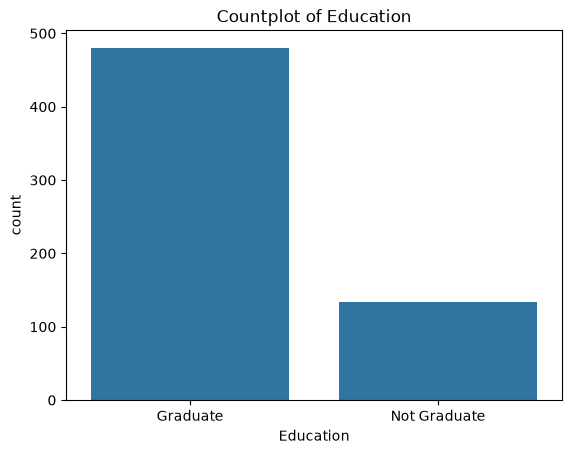

<Figure size 640x480 with 0 Axes>

In [35]:
sns.countplot(x='Education', data=df)
plt.title('Countplot of Education')
plt.show()
plt.savefig('countplot_education.png')  #save the countplot as an image file

In [36]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,145.752443,342.410423,0.855049
std,6109.041673,2926.248369,84.107233,64.428629,0.352339
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2877.500000,0.000000,100.250000,360.000000,1.000000
50%,3812.500000,1188.500000,128.000000,360.000000,1.000000
75%,5795.000000,2297.250000,164.750000,360.000000,1.000000
max,81000.000000,41667.000000,700.000000,480.000000,1.000000


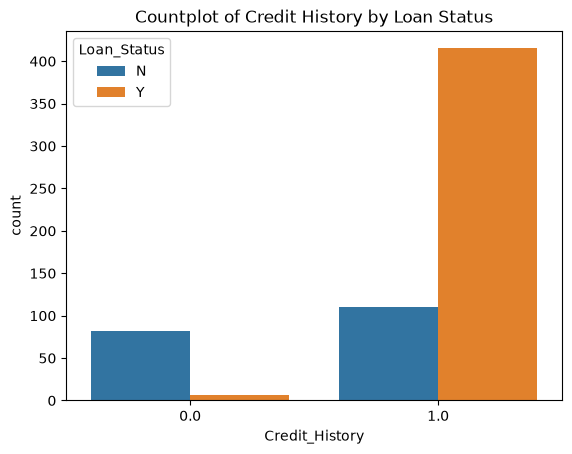

<Figure size 640x480 with 0 Axes>

In [37]:
sns.countplot(x='Credit_History',hue='Loan_Status', data=df)
plt.title('Countplot of Credit History by Loan Status')
plt.show()
plt.savefig('countplot_credit_history_loan_status.png')  #save the countplot as an image file

In [38]:
df.corr(numeric_only=True)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
ApplicantIncome,1.000000,-0.116605,0.565181,-0.046531,-0.018615
CoapplicantIncome,-0.116605,1.000000,0.189218,-0.059383,0.011134
LoanAmount,0.565181,0.189218,1.000000,0.036960,-0.000607
Loan_Amount_Term,-0.046531,-0.059383,0.036960,1.000000,-0.004705
Credit_History,-0.018615,0.011134,-0.000607,-0.004705,1.000000


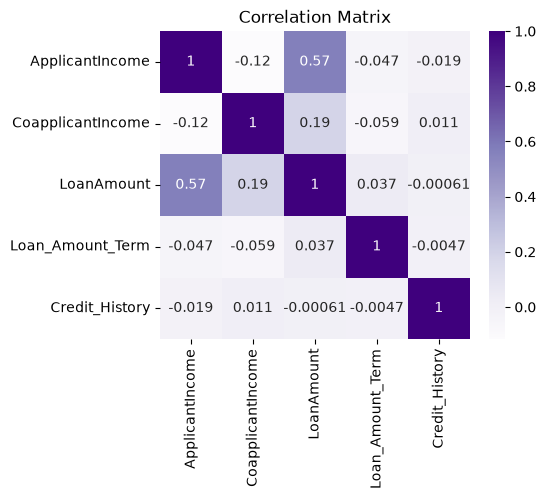

<Figure size 640x480 with 0 Axes>

In [39]:
plt.figure(figsize=(5,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Purples')
plt.title('Correlation Matrix')
plt.show()
plt.savefig('correlation_matrix.png')  #save the heatmap as an image file

FEATURE SELECTION


In [40]:
x = df.drop('Loan_Status', axis=1)  #features   
y = df['Loan_Status']  #target variable 

In [41]:
x
y

0      Y
1      N
2      Y
3      Y
4      Y
      ..
609    Y
610    Y
611    Y
612    Y
613    N
Name: Loan_Status, Length: 614, dtype: str

In [42]:
#separating numerical and categorical features

num_cols = x.select_dtypes(include=['int64', 'float64']).columns
cat_cols = x.select_dtypes(include=['object']).columns

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='str')
Categorical columns: Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area'],
      dtype='str')


C:\Users\priya\AppData\Local\Temp\ipykernel_8328\3157294522.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = x.select_dtypes(include=['object']).columns


In [43]:
x = pd.get_dummies(x, columns=cat_cols, drop_first=True)  #one-hot encoding for categorical features
x.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_ID_LP001003,Loan_ID_LP001005,Loan_ID_LP001006,Loan_ID_LP001008,Loan_ID_LP001011,...,Loan_ID_LP002990,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
1,4583,1508.0,128.0,360.0,1.0,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False
2,3000,0.0,66.0,360.0,1.0,False,True,False,False,False,...,False,True,True,False,False,False,False,True,False,True
3,2583,2358.0,120.0,360.0,1.0,False,False,True,False,False,...,False,True,True,False,False,False,True,False,False,True
4,6000,0.0,141.0,360.0,1.0,False,False,False,True,False,...,False,True,False,False,False,False,False,False,False,True


In [44]:
x.astype(int)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_ID_LP001003,Loan_ID_LP001005,Loan_ID_LP001006,Loan_ID_LP001008,Loan_ID_LP001011,...,Loan_ID_LP002990,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0,128,360,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
1,4583,1508,128,360,1,1,0,0,0,0,...,0,1,1,1,0,0,0,0,0,0
2,3000,0,66,360,1,0,1,0,0,0,...,0,1,1,0,0,0,0,1,0,1
3,2583,2358,120,360,1,0,0,1,0,0,...,0,1,1,0,0,0,1,0,0,1
4,6000,0,141,360,1,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900,0,71,360,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
610,4106,0,40,180,1,0,0,0,0,0,...,0,1,1,0,0,1,0,0,0,0
611,8072,240,253,360,1,0,0,0,0,0,...,0,1,1,1,0,0,0,0,0,1
612,7583,0,187,360,1,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,1


FEATURE SCALING


In [45]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler

scaler = StandardScaler()

x[num_cols] = scaler.fit_transform(x[num_cols])  #scaling numerical features

x

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_ID_LP001003,Loan_ID_LP001005,Loan_ID_LP001006,Loan_ID_LP001008,Loan_ID_LP001011,...,Loan_ID_LP002990,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,0.072991,-0.554487,-0.211241,0.273231,0.411733,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
1,-0.134412,-0.038732,-0.211241,0.273231,0.411733,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False
2,-0.393747,-0.554487,-0.948996,0.273231,0.411733,False,True,False,False,False,...,False,True,True,False,False,False,False,True,False,True
3,-0.462062,0.251980,-0.306435,0.273231,0.411733,False,False,True,False,False,...,False,True,True,False,False,False,True,False,False,True
4,0.097728,-0.554487,-0.056551,0.273231,0.411733,False,False,False,True,False,...,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,-0.410130,-0.554487,-0.889500,0.273231,0.411733,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
610,-0.212557,-0.554487,-1.258378,-2.522836,0.411733,False,False,False,False,False,...,False,True,True,False,False,True,False,False,False,False
611,0.437174,-0.472404,1.276168,0.273231,0.411733,False,False,False,False,False,...,False,True,True,True,False,False,False,False,False,True
612,0.357064,-0.554487,0.490816,0.273231,0.411733,False,False,False,False,False,...,False,True,True,False,True,False,False,False,False,True


In [46]:
scaler = MinMaxScaler()
x[num_cols] = scaler.fit_transform(x[num_cols])  #scaling numerical features

In [47]:
x

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_ID_LP001003,Loan_ID_LP001005,Loan_ID_LP001006,Loan_ID_LP001008,Loan_ID_LP001011,...,Loan_ID_LP002990,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,0.070489,0.000000,0.172214,0.743590,1.0,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
1,0.054830,0.036192,0.172214,0.743590,1.0,True,False,False,False,False,...,False,True,True,True,False,False,False,False,False,False
2,0.035250,0.000000,0.082489,0.743590,1.0,False,True,False,False,False,...,False,True,True,False,False,False,False,True,False,True
3,0.030093,0.056592,0.160637,0.743590,1.0,False,False,True,False,False,...,False,True,True,False,False,False,True,False,False,True
4,0.072356,0.000000,0.191027,0.743590,1.0,False,False,False,True,False,...,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,0.034014,0.000000,0.089725,0.743590,1.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
610,0.048930,0.000000,0.044863,0.358974,1.0,False,False,False,False,False,...,False,True,True,False,False,True,False,False,False,False
611,0.097984,0.005760,0.353111,0.743590,1.0,False,False,False,False,False,...,False,True,True,True,False,False,False,False,False,True
612,0.091936,0.000000,0.257598,0.743590,1.0,False,False,False,False,False,...,False,True,True,False,True,False,False,False,False,True


In [48]:
x = df.drop('Loan_Status', axis=1)  #features
x= pd.get_dummies(x,drop_first=True,dtype=int)
y = df['Loan_Status']  #target variable


In [49]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


In [50]:
x_train.shape


(491, 627)

In [51]:
x_test.shape

(123, 627)

In [52]:
y_train.shape


(491,)

In [53]:
y_test.shape

(123,)

In [54]:
scaler = StandardScaler()

x_train[num_cols] = scaler.fit_transform(x_train[num_cols])  #scaling numerical features
x_test[num_cols] = scaler.transform(x_test[num_cols])  #scaling numerical features        #this prevents data leakage by using the same scaler fitted on the training data to transform the test data

In [55]:
from sklearn.linear_model import LogisticRegression

In [56]:
model = LogisticRegression()
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [57]:
y_pred = model.predict(x_test)
y_pred

array(['N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'N', 'N', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'N'], dtype=object)

In [58]:
from calendar import c

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
cr = classification_report(y_test, y_pred, output_dict=True)



0.8617886178861789


In [59]:
cm.tolist()

[[22, 16], [1, 84]]

In [60]:
cr

{'N': {'precision': 0.9565217391304348,
  'recall': 0.5789473684210527,
  'f1-score': 0.7213114754098361,
  'support': 38.0},
 'Y': {'precision': 0.84,
  'recall': 0.9882352941176471,
  'f1-score': 0.9081081081081082,
  'support': 85.0},
 'accuracy': 0.8617886178861789,
 'macro avg': {'precision': 0.8982608695652174,
  'recall': 0.7835913312693499,
  'f1-score': 0.8147097917589721,
  'support': 123.0},
 'weighted avg': {'precision': 0.8759985860728171,
  'recall': 0.8617886178861789,
  'f1-score': 0.850398579307016,
  'support': 123.0}}

In [61]:
from sklearn.metrics import roc_auc_score, roc_curve
y_prob = model.predict_proba(x_test)[:, 1]  #probabilities of the positive class
roc_auc = roc_auc_score(y_test, y_prob)
print(roc_auc)

0.8523219814241485


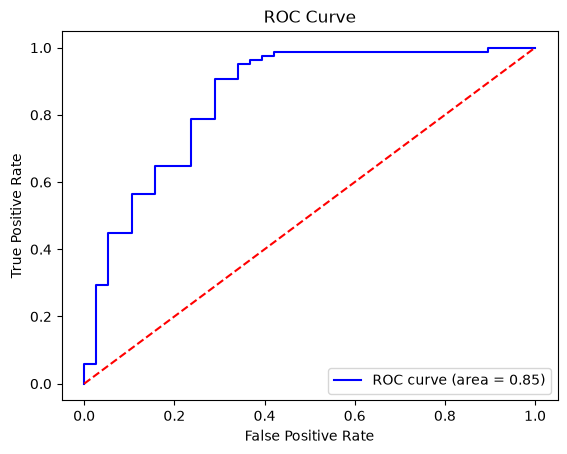

<Figure size 640x480 with 0 Axes>

In [62]:
y_prob = model.predict_proba(x_test)[:, 1]  #probabilities of the positive class

fpr,tpr,thresholds = roc_curve(y_test, y_prob, pos_label='Y')
roc_auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0,1], [0,1], color='red', linestyle='--')  #diagonal line for random classifier
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()
plt.savefig('roc_curve.png')  #save the ROC curve as an image file


In [63]:
from sklearn.tree import DecisionTreeClassifier

In [64]:
dt_model = DecisionTreeClassifier(random_state=42)

In [65]:
dt_model.fit(x_train, y_train)  #fit()- trains the model on the training data

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [66]:
dt_pred = dt_model.predict(x_test) #predict()- makes predictions on the test data

In [67]:
dt_pred

array(['N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'N', 'N', 'Y', 'N', 'N', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'N', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'Y', 'N', 'N', 'Y', 'N'], dtype=object)

In [68]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_accuracy

0.8048780487804879

In [69]:
dt_cm = confusion_matrix(y_test, dt_pred)
dt_cm

array([[22, 16],
       [ 8, 77]])

In [70]:
dt_cr = classification_report(y_test, dt_pred, output_dict=True)
dt_cr

{'N': {'precision': 0.7333333333333333,
  'recall': 0.5789473684210527,
  'f1-score': 0.6470588235294118,
  'support': 38.0},
 'Y': {'precision': 0.8279569892473119,
  'recall': 0.9058823529411765,
  'f1-score': 0.8651685393258427,
  'support': 85.0},
 'accuracy': 0.8048780487804879,
 'macro avg': {'precision': 0.7806451612903226,
  'recall': 0.7424148606811145,
  'f1-score': 0.7561136814276272,
  'support': 123.0},
 'weighted avg': {'precision': 0.7987236646560013,
  'recall': 0.8048780487804879,
  'f1-score': 0.797785049892799,
  'support': 123.0}}

In [71]:
from sklearn.ensemble import RandomForestClassifier

In [72]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [73]:
rf_model.fit(x_train, y_train)  #fit()- trains the model on the training data

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [74]:
rf_pred = rf_model.predict(x_test) #predict()- makes predictions on the test data

In [75]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_accuracy

0.8455284552845529

In [76]:
rf_cm = confusion_matrix(y_test, rf_pred)
rf_cm

array([[21, 17],
       [ 2, 83]])

In [77]:
rf_cr = classification_report(y_test, rf_pred, output_dict=True)        
rf_cr

{'N': {'precision': 0.9130434782608695,
  'recall': 0.5526315789473685,
  'f1-score': 0.6885245901639344,
  'support': 38.0},
 'Y': {'precision': 0.83,
  'recall': 0.9764705882352941,
  'f1-score': 0.8972972972972973,
  'support': 85.0},
 'accuracy': 0.8455284552845529,
 'macro avg': {'precision': 0.8715217391304347,
  'recall': 0.7645510835913313,
  'f1-score': 0.7929109437306159,
  'support': 123.0},
 'weighted avg': {'precision': 0.8556557087310004,
  'recall': 0.8455284552845529,
  'f1-score': 0.8327984121666648,
  'support': 123.0}}

In [78]:
from sklearn.neighbors import KNeighborsClassifier

In [79]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [80]:
knn_model.fit(x_train, y_train)  #fit()- trains the model on the training data  

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['N','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [81]:
knn_pred = knn_model.predict(x_test) #predict()- makes predictions on the test data
knn_pred

array(['N', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'N', 'N', 'N', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'N'], dtype=object)

In [82]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_accuracy

0.8617886178861789

In [83]:
knn_cm = confusion_matrix(y_test, knn_pred)
knn_cm

array([[24, 14],
       [ 3, 82]])

In [84]:
knn_cr = classification_report(y_test, knn_pred, output_dict=True)
knn_cr

{'N': {'precision': 0.8888888888888888,
  'recall': 0.631578947368421,
  'f1-score': 0.7384615384615385,
  'support': 38.0},
 'Y': {'precision': 0.8541666666666666,
  'recall': 0.9647058823529412,
  'f1-score': 0.9060773480662984,
  'support': 85.0},
 'accuracy': 0.8617886178861789,
 'macro avg': {'precision': 0.8715277777777777,
  'recall': 0.798142414860681,
  'f1-score': 0.8222694432639184,
  'support': 123.0},
 'weighted avg': {'precision': 0.8648938572719059,
  'recall': 0.8617886178861789,
  'f1-score': 0.8542936020095432,
  'support': 123.0}}

In [85]:
from sklearn.svm import SVC

In [86]:
svm_model = SVC(kernel='rbf', probability=True, random_state=42)  

In [87]:
svm_model.fit(x_train, y_train)  #fit()- trains the model on the training data

c:\Users\priya\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [88]:
svm_pred = svm_model.predict(x_test) #predict()- makes predictions on the test data
svm_pred

array(['N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'N', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'N'], dtype=object)

In [89]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_accuracy

0.8455284552845529

In [90]:
svm_cm = confusion_matrix(y_test, svm_pred)
svm_cm

array([[20, 18],
       [ 1, 84]])

In [91]:
svm_cr = classification_report(y_test, svm_pred, output_dict=True)
svm_cr

{'N': {'precision': 0.9523809523809523,
  'recall': 0.5263157894736842,
  'f1-score': 0.6779661016949152,
  'support': 38.0},
 'Y': {'precision': 0.8235294117647058,
  'recall': 0.9882352941176471,
  'f1-score': 0.8983957219251337,
  'support': 85.0},
 'accuracy': 0.8455284552845529,
 'macro avg': {'precision': 0.8879551820728291,
  'recall': 0.7572755417956656,
  'f1-score': 0.7881809118100245,
  'support': 123.0},
 'weighted avg': {'precision': 0.8633372048006195,
  'recall': 0.8455284552845529,
  'f1-score': 0.8302955140491314,
  'support': 123.0}}

In [92]:
from sklearn.naive_bayes import GaussianNB

In [93]:
nb_model = GaussianNB()

In [94]:
nb_model.fit(x_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[154.,337.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.31,0.69]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U1](2,)","['N','Y']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](627,)","['ApplicantIncome','CoapplicantIncome','LoanAmount',..., 'Self_Employed_Yes','Property_Area_Semiurban','Property_Area_Urban']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,627
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 627)","[[ 0.02, 0.07, 0.01,..., 0.14, 0.27, 0.36], [-0.01,-0.03,-0. ,..., 0.13, 0.42, 0.31]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 627)","[[1.3 ,2.08,0.86,...,0.12,0.2 ,0.23], [0.86,0.5 ,1.06,...,0.11,0.24,0.22]]"


In [95]:
nb_pred = nb_model.predict(x_test)
nb_pred

array(['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N'], dtype='<U1')

In [96]:
nb_model = GaussianNB(var_smoothing=1e-6)

nb_model.fit(x_train, y_train)

nb_pred = nb_model.predict(x_test)

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Predictions:")
print(pd.Series(nb_pred).value_counts())

Naive Bayes Accuracy: 0.3089430894308943
Predictions:
N    123
Name: count, dtype: int64


In [97]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nFirst 20 feature names:")
print(x_train.columns[:20].tolist())

print("\nFirst 5 rows:")
display(x_train.head())

X_train shape: (491, 627)
X_test shape: (123, 627)
y_train shape: (491,)
y_test shape: (123,)

First 20 feature names:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_ID_LP001003', 'Loan_ID_LP001005', 'Loan_ID_LP001006', 'Loan_ID_LP001008', 'Loan_ID_LP001011', 'Loan_ID_LP001013', 'Loan_ID_LP001014', 'Loan_ID_LP001018', 'Loan_ID_LP001020', 'Loan_ID_LP001024', 'Loan_ID_LP001027', 'Loan_ID_LP001028', 'Loan_ID_LP001029', 'Loan_ID_LP001030', 'Loan_ID_LP001032']

First 5 rows:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_ID_LP001003,Loan_ID_LP001005,Loan_ID_LP001006,Loan_ID_LP001008,Loan_ID_LP001011,...,Loan_ID_LP002990,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
154,-0.352802,-0.563228,-1.131588,0.280691,0.397516,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
239,-0.343346,-0.563228,-0.592309,0.280691,0.397516,0,0,0,0,0,...,0,1,1,1,0,0,0,0,1,0
448,-0.339471,0.050405,0.040758,0.280691,-2.515623,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,0
471,-0.445963,-0.024953,-0.393010,-2.486768,-2.515623,0,0,0,0,0,...,0,1,1,1,0,0,1,0,0,0
273,-0.451078,0.234495,0.040758,0.280691,0.397516,0,0,0,0,0,...,0,1,1,0,0,0,0,0,1,0


In [98]:
x_train = x_train.loc[:, ~x_train.columns.str.startswith('Loan_ID')]

x_test = x_test.loc[:, ~x_test.columns.str.startswith('Loan_ID')]
print(x_train.shape)
print(x_test.shape)

(491, 14)
(123, 14)


In [99]:
nb_model = GaussianNB()

nb_model.fit(x_train, y_train)

nb_pred = nb_model.predict(x_test)

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)

Naive Bayes Accuracy: 0.8455284552845529


In [100]:
nb_cm = confusion_matrix(y_test,nb_pred)
nb_cm

array([[22, 16],
       [ 3, 82]])

In [101]:
nb_cr = classification_report(y_test,nb_pred)
nb_cr

'              precision    recall  f1-score   support\n\n           N       0.88      0.58      0.70        38\n           Y       0.84      0.96      0.90        85\n\n    accuracy                           0.85       123\n   macro avg       0.86      0.77      0.80       123\nweighted avg       0.85      0.85      0.84       123\n'

In [102]:

from sklearn.ensemble import GradientBoostingClassifier

In [103]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate = 0.1,
    random_state = 42
)

In [104]:
gb_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [105]:
gb_pred = gb_model.predict(x_test)

In [106]:
gb_accuracy = accuracy_score(y_test,nb_pred)
gb_accuracy

0.8455284552845529

In [107]:
gb_cm = confusion_matrix(y_test,gb_pred)
gb_cm

array([[21, 17],
       [ 4, 81]])

In [108]:
gb_cr = classification_report(y_test,gb_pred)
gb_cr

'              precision    recall  f1-score   support\n\n           N       0.84      0.55      0.67        38\n           Y       0.83      0.95      0.89        85\n\n    accuracy                           0.83       123\n   macro avg       0.83      0.75      0.78       123\nweighted avg       0.83      0.83      0.82       123\n'

In [109]:

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree',
              'Random Forest', 'KNN', 'SVM',
              'Naive Bayes', 'Gradient Boosting'],
    'Accuracy': [86, 80.4, 84, 86.17, 84.55, 84.55, 84.55]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,86.00
1,Decision Tree,80.40
2,Random Forest,84.00
3,KNN,86.17
4,SVM,84.55
5,Naive Bayes,84.55
6,Gradient Boosting,84.55


Accuracy Visualization


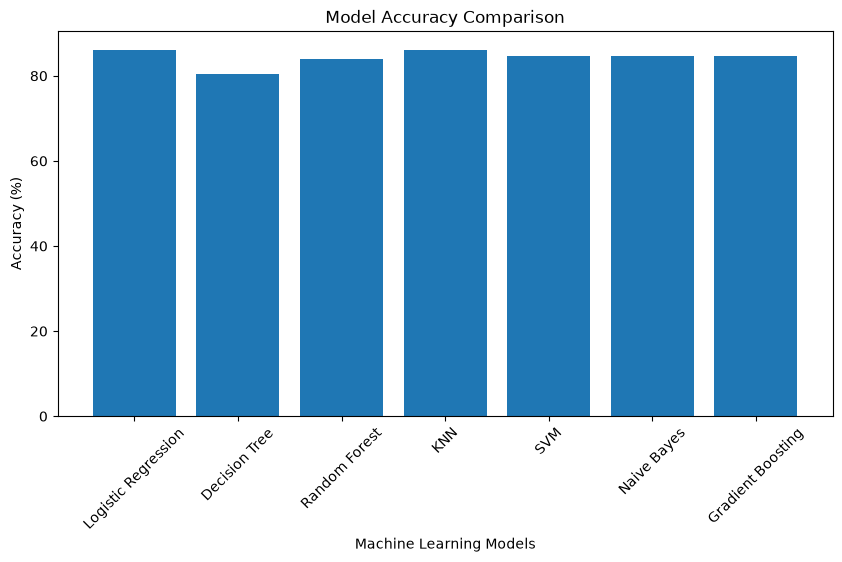

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(model_comparison['Model'],
        model_comparison['Accuracy'])

plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')

plt.xticks(rotation=45)
plt.show()

Best Model Selection

In [111]:
best_model = model_comparison.loc[
    model_comparison['Accuracy'].idxmax()
]

print("Best Model:", best_model['Model'])
print("Best Accuracy:", best_model['Accuracy'], "%")

Best Model: KNN
Best Accuracy: 86.17 %


Model Re training


In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [113]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42
    )
}

for name, model in models.items():
    model.fit(x_train, y_train)

print("All 7 models retrained successfully!")

c:\Users\priya\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


All 7 models retrained successfully!


In [114]:
from sklearn.metrics import accuracy_score

new_results = []

for name, model in models.items():
    predictions = model.predict(x_test)
    accuracy = accuracy_score(y_test, predictions) * 100

    new_results.append({
        'Model': name,
        'Accuracy': round(accuracy, 2)
    })

new_comparison = pd.DataFrame(new_results)

new_comparison

,Model,Accuracy
0,Logistic Regression,86.18
1,Decision Tree,71.54
2,Random Forest,83.74
3,KNN,86.18
4,SVM,84.55
5,Naive Bayes,84.55
6,Gradient Boosting,82.93


In [115]:
best_model = new_comparison.loc[
    new_comparison['Accuracy'].idxmax()
]

print("Final Best Model:", best_model['Model'])
print("Final Accuracy:", best_model['Accuracy'], "%")

Final Best Model: Logistic Regression
Final Accuracy: 86.18 %
